# Day 4: eight-agent risk sharing
## Organized, self-contained OOP notebook
Prepared for Nouman Bashir with ChatGPT assistance. Both Day 4 roles were delegated.

**In Colab:** open this notebook and choose **Runtime → Run all**. Use a normal CPU runtime.
No ZIP, dataset, PDF, previous notebook, or Drive connection is required.
NumPy, SciPy, and Matplotlib are included in standard Colab runtimes.

Read the explanation before each code cell. Every import appears in the first code cell.
Settings are defined once; the experiment is run once; the same results are then shown,
saved, and plotted. The final cell optionally downloads the generated results.

### How the classes fit together
| Class | One responsibility |
|---|---|
| `ExperimentConfig` | Store settings in one place |
| `RiskSharingModel` | Own inputs and calculate welfare and gradients |
| `AllocationConstraints` | Enforce feasible shares and solve the linear subproblem |
| `SolverResult` | Keep an allocation and its convergence records together |
| `FrankWolfeSolver` | Perform the optimization loop |
| `Example2Benchmark` | Calculate the analytic answer and scalar check |
| `GradientCheck`, `OracleCheck` | Check derivatives and the linear oracle |
| `OptimizerCheck`, `FeasibilityCheck` | Check optimization and rejection of invalid allocations |
| `NumericalValidator` | Coordinate those checks |
| `ResultAnalysis` | Calculate acceptance checks and error comparisons |
| `ResultTables` | Build comparison tables and display results |
| `CSVWriter`, `AllocationTable` | Write CSV files and construct allocation rows |
| `ResultFiles`, `ResultDownload` | Save outputs and prepare an optional download |
| `ResultPlots` | Build, save, and display the figures |
| `Day4Experiment` | Connect the components and coordinate the run |

This uses **encapsulation** (related data and behavior in a class), **composition**
(classes working together), and programming fundamentals: descriptive names, small methods,
functions, conditions, loops, reusable calculations, and input validation.

`self` means the current object. A method is a function belonging to a class.
`@dataclass` generates routine initialization code. `@property` exposes a calculated value.
A leading underscore marks a method intended for the class's internal use.

## 1. Python reading guide

- `class` defines an object type; `def` defines a function or method.
- `self` means the current object; `self.model` is a value stored in that object.
- `__init__` runs when an object is created. `__post_init__` validates a dataclass after creation.
- `@dataclass` creates routine initialization code; `frozen=True` prevents attribute reassignment.
- `@classmethod` receives the class as `cls`; `@staticmethod` needs neither `self` nor `cls`.
- `@property` lets you read a calculated value like an attribute, without parentheses.
- `array[:, None]` turns a vector into a column; `array[None, :]` makes it a row.
- `array[::-1]` reverses rows; `array[:, group]` selects agent columns.
- `reshape` restores a table's dimensions; `ravel` flattens a table into one vector.
- `axis=0` works down the rows; `axis=1` works across the columns.
- `enumerate` gives an index and value; `zip` pairs entries from sequences.
- A comprehension builds a list or dictionary using a compact loop.
- `lambda x: expression` is a small function that receives `x` and returns the expression.
- `assert` stops this notebook if an expected check fails. `raise` reports an invalid input or state.
- `try` / `except` handles an expected failure. `with` closes a file automatically after use.
- `**dictionary` inserts its entries into another dictionary; `f"...{value}..."` inserts a value into text.

Brief comments introduce each class and function. A few inline comments explain non-obvious
steps, including all four lambdas.

## 2. Import dependencies once

All standard and scientific imports are collected here. The optional Colab import is only used
when downloading results; it never requests an upload.

In [1]:
from dataclasses import asdict, dataclass, field, replace
from datetime import datetime, timezone
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile
import csv
import json
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.integrate import quad
from scipy.optimize import Bounds, LinearConstraint, brentq, linprog, minimize

# Optional Colab support is imported once, alongside every other dependency.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None


## 3. Keep every setting in one place

Change the defaults in this class to change the experiment. `frozen=True` prevents accidental
reassignment of settings. Pareto weights specify how strongly each agent counts in welfare.
The analytic benchmark below requires the Example 2 agent types and equal weights.

The allocation tolerance and welfare gap tolerance serve different purposes. A small welfare gap
alone does not certify a small allocation error.

In [2]:
# Class: The single place to change experiment settings.
@dataclass(frozen=True)
class ExperimentConfig:
    """The single place to change experiment settings."""
    states: int = 400
    gap_tolerance: float = 5e-6
    allocation_tolerance: float = 0.0025
    feasibility_tolerance: float = 1e-10
    roundoff_tolerance: float = 1e-12
    max_updates: int = 20000
    validation_seed: int = 20261009
    output_directory: str = "day4_results"
    agent_types: tuple = ("h2", "h2", "h1", "h1", "h1", "h1", "h1", "h2")
    pareto_weights: tuple = (1.,) * 8

    # Function: Check that the grid size, update limit, tolerances, and output folder are valid.
    def __post_init__(self):
        if not isinstance(self.states, int) or self.states < 1:
            raise ValueError("states must be a positive integer")
        if not isinstance(self.max_updates, int) or self.max_updates < 0:
            raise ValueError("max_updates must be a nonnegative integer")
        tolerances = (self.gap_tolerance, self.allocation_tolerance,
                      self.feasibility_tolerance, self.roundoff_tolerance)
        if not all(np.isfinite(x) and x > 0 for x in tolerances):
            raise ValueError("All tolerances must be finite and positive")
        if not self.output_directory:
            raise ValueError("Choose an output directory")


## 4. Define the economic model

A row is a wealth state; a column is an agent. `from_config` generates 400 midpoint states
of probability 1/400. Total wealth is uniform on [0,1], so wealth and rank coincide here;
the model keeps them as separate inputs.

Agents 3–7 use $h_1(r,c)=\log(1+\sqrt r+c)$.
Agents 1, 2, and 8 use $h_2(r,c)=\log(1+r^{2/3}+c)$.
Here $c$ is the agent's consumption and $r$ is the wealth state's rank.

`objective` calculates total expected weighted utility. `gradient` measures the benefit of
an extra amount of consumption. Both use the same cached `offsets`, calculated once during
initialization. `[:, None]` turns a vector into a column so NumPy can align states with agents.

In [3]:
# Class: Hold model inputs and calculate utility, welfare, and its gradient.
@dataclass(frozen=True)
class RiskSharingModel:
    """Hold model inputs and calculate utility, welfare, and its gradient."""
    wealth: np.ndarray
    ranks: np.ndarray
    probabilities: np.ndarray
    weights: np.ndarray
    agent_types: tuple
    offsets: np.ndarray = field(init=False, repr=False)

    # Function: Validate and protect model inputs, then calculate the utility offsets once.
    def __post_init__(self):
        # Copy and protect inputs so later cells cannot accidentally change them.
        for name in ("wealth", "ranks", "probabilities", "weights"):
            value = np.array(getattr(self, name), dtype=float, copy=True)
            if value.ndim != 1 or not value.size or not np.isfinite(value).all():
                raise ValueError(f"{name} must be a finite, nonempty vector")
            value.setflags(write=False)
            object.__setattr__(self, name, value)
        types = tuple(self.agent_types)
        object.__setattr__(self, "agent_types", types)
        if self.ranks.shape != self.wealth.shape or self.probabilities.shape != self.wealth.shape:
            raise ValueError("One rank and probability are required per wealth state")
        if np.any(self.wealth < 0) or np.any(np.diff(self.wealth) < 0):
            raise ValueError("Wealth must be nonnegative and nondecreasing")
        if np.any((self.ranks <= 0) | (self.ranks >= 1)) or np.any(np.diff(self.ranks) <= 0):
            raise ValueError("Ranks must increase strictly within (0, 1)")
        if np.any(self.probabilities < 0) or not np.isclose(self.probabilities.sum(), 1, rtol=0, atol=1e-12):
            raise ValueError("Probabilities must be nonnegative and sum to one")
        if np.any(self.weights <= 0) or len(types) != self.weights.size:
            raise ValueError("One positive Pareto weight is required per agent")
        if any(t not in ("h1", "h2") for t in types):
            raise ValueError("Each agent type must be h1 or h2")
        powers = np.array([.5 if t == "h1" else 2/3 for t in types])
        offsets = 1 + self.ranks[:, None] ** powers[None, :]
        offsets.setflags(write=False)
        object.__setattr__(self, "offsets", offsets)

    # Function: Build a midpoint wealth grid from settings and return a model object.
    @classmethod
    def from_config(cls, config, states=None):
        """Generate the midpoint grid; no uploaded data are needed."""
        count = config.states if states is None else states
        ranks = (np.arange(count) + .5) / count
        return cls(ranks.copy(), ranks, np.full(count, 1/count),
                   config.pareto_weights, config.agent_types)

    # Function: Return the number of states and agents as a pair: (states, agents).
    @property
    def shape(self):
        return self.wealth.size, self.weights.size  # (states, agents)

    # Function: Check that shares have the right dimensions and are finite and nonnegative.
    def consumption(self, values):
        """Validate an allocation's shape and utility domain."""
        c = np.asarray(values, dtype=float)
        if c.shape != self.shape or not np.isfinite(c).all() or np.any(c < 0):
            raise ValueError(f"Consumption must be finite, nonnegative, and shape {self.shape}")
        return c

    # Function: Return total expected weighted satisfaction as one welfare number.
    def objective(self, consumption):
        c = self.consumption(consumption)
        return float(np.sum(self.probabilities[:, None] * self.weights[None, :]
                            * np.log(self.offsets + c)))

    # Function: Return the extra welfare benefit per unit of consumption at every table entry.
    def gradient(self, consumption):
        c = self.consumption(consumption)
        return self.probabilities[:, None] * self.weights[None, :] / (self.offsets + c)

    # Function: Create a feasible starting table by dividing each state's wealth equally.
    def equal_sharing(self):
        return np.repeat(self.wealth[:, None] / self.shape[1], self.shape[1], axis=1)


## 5. Define feasible allocations and the oracle

An allocation must use the exact available wealth in each state, give nobody negative consumption,
and never reduce any agent's share as total wealth rises.

The oracle solves a linear subproblem, using tail sums of gradient values. Assigning a consumption
increment at one state also affects higher states because of monotonicity. The largest tail score
wins that increment; exact ties are shared equally. The solver calls this method rather than
reimplementing the constraint logic.

In [4]:
# Class: Own budget balance, nonnegativity, monotonicity, and the linear oracle.
class AllocationConstraints:
    """Own budget balance, nonnegativity, monotonicity, and the linear oracle."""
    # Function: Store the wealth vector, required table shape, and feasibility tolerance.
    def __init__(self, model, tolerance=1e-10):
        self.wealth = model.wealth
        self.shape = model.shape
        self.tolerance = tolerance

    # Function: Check budget balance, nonnegative shares, and monotonicity; return residuals.
    def check(self, allocation):
        c = np.asarray(allocation, dtype=float)
        if c.shape != self.shape or not np.isfinite(c).all():
            raise AssertionError("Allocation has an invalid shape or nonfinite values")
        increments = np.diff(np.vstack((np.zeros((1, self.shape[1])), c)), axis=0)
        residuals = {"budget_residual": float(np.max(abs(c.sum(axis=1) - self.wealth))),
                     "minimum_consumption": float(c.min()),
                     "minimum_increment": float(increments.min())}
        if (residuals["budget_residual"] > self.tolerance
                or min(residuals["minimum_consumption"], residuals["minimum_increment"]) < -self.tolerance):
            raise AssertionError(residuals)
        return residuals

    # Function: Find the best feasible allocation for the supplied linear gradient scores.
    def linear_oracle(self, gradient):
        """Allocate wealth increments using tail sums of the gradient."""
        g = np.asarray(gradient, dtype=float)
        if g.shape != self.shape or not np.isfinite(g).all():
            raise ValueError("Gradient must be finite and match the allocation shape")
        scores = np.cumsum(g[::-1], axis=0)[::-1]
        winners = scores == scores.max(axis=1, keepdims=True)
        wealth_increments = np.diff(np.r_[0., self.wealth])
        # Share exact ties equally; cumulative sums reconstruct consumption.
        increments = wealth_increments[:, None] * winners / winners.sum(axis=1, keepdims=True)
        return np.cumsum(increments, axis=0)


## 6. Define the solver and its result object

The solver starts with equal sharing. Each iteration calculates welfare and its gradient, asks
the oracle for a feasible candidate, and moves toward it using a bisection line search.
No analytic answer is passed to this class.

`SolverResult` groups the allocation, history, and convergence status. Its `final` property returns
the last iteration record. The stopping rule uses the finite-grid welfare gap. A run that reaches
its update limit or stalls must not report convergence.

In [5]:
# Class: Keep the solution and convergence evidence together.
@dataclass
class SolverResult:
    """Keep the solution and convergence evidence together."""
    allocation: np.ndarray
    history: list
    converged: bool

    # Function: Read the last saved iteration without copying the history.
    @property
    def final(self):
        return self.history[-1]


# Class: Improve a feasible allocation using gradients, an oracle, and line search.
class FrankWolfeSolver:
    """Improve a feasible allocation using gradients, an oracle, and line search."""
    # Function: Connect this solver to its model, feasibility rules, and settings.
    def __init__(self, model, constraints, config):
        self.model = model
        self.constraints = constraints
        self.config = config

    # Function: Use derivative signs and bisection to choose a step between zero and one.
    def _line_search(self, allocation, direction):
        # A positive derivative means a slightly larger step improves welfare.
        def slope(step):
            return float(np.sum(self.model.gradient(allocation + step*direction) * direction))
        if slope(0) <= 0:
            return 0.
        if slope(1) >= 0:
            return 1.
        left, right = 0., 1.
        for _ in range(42):
            middle = (left + right) / 2
            if slope(middle) > 0:
                left = middle
            else:
                right = middle
        return (left + right) / 2

    # Function: Repeat oracle and line-search steps until the welfare gap is small or the run stops.
    def solve(self):
        c, history = self.model.equal_sharing(), []
        for iteration in range(self.config.max_updates + 1):
            residuals = self.constraints.check(c)
            value, gradient = self.model.objective(c), self.model.gradient(c)
            candidate = self.constraints.linear_oracle(gradient)
            self.constraints.check(candidate)
            direction = candidate - c
            gap = float(np.sum(gradient * direction))
            if gap < -self.config.roundoff_tolerance:
                raise AssertionError("An exact linear oracle cannot have a negative gap")
            gap = max(gap, 0.)  # clip harmless floating point rounding only
            record = {"iteration": iteration, "welfare": value, "gap": gap,
                      "upper_bound": value + gap, **residuals, "step": None}
            history.append(record)
            converged = gap <= self.config.gap_tolerance
            if converged or iteration == self.config.max_updates:
                return SolverResult(c, history, converged)
            record["step"] = self._line_search(c, direction)
            updated = c + record["step"] * direction
            self.constraints.check(updated)
            if self.model.objective(updated) < value - self.config.roundoff_tolerance:
                raise AssertionError("Welfare decreased")
            if record["step"] == 0 or np.array_equal(updated, c):
                return SolverResult(c, history, False)
            c = updated


## 7. Define the analytic benchmark separately

Let $b(s)$ be the share of **each** of five h1 agents and $a(s)$ the share of **each** of three h2 agents.
The budget is $5b+3a=s$. When both types receive positive shares, equal marginal utilities give
$\sqrt{s}+b=s^{2/3}+a$. Therefore:

$$b(s)=\max\{[s+3(s^{2/3}-\sqrt{s})]/8,0\},\qquad a(s)=[s-5b(s)]/3.$$

The h1 share activates at approximately 0.298995684337. The formula is evaluated separately from
the optimizer. `scalar_allocation` also solves a marginal utility equation without using the group
formula. The full proof, including monotonicity, appears at the end of this notebook.

In [6]:
# Class: Supply the analytic answer and a separate scalar-equation check.
class Example2Benchmark:
    """Supply the analytic answer and a separate scalar-equation check."""
    # Function: Identify the two agent groups and reject settings outside this analytic formula.
    def __init__(self, model):
        types = np.array(model.agent_types)
        self.h1 = np.flatnonzero(types == "h1")
        self.h2 = np.flatnonzero(types == "h2")
        if model.shape[1] != 8 or len(self.h1) != 5 or len(self.h2) != 3:
            raise ValueError("Example 2 requires five h1 and three h2 agents")
        if not np.array_equal(model.weights, np.ones(8)):
            raise ValueError("The group formula requires unit Pareto weights")
        if not np.array_equal(model.wealth, model.ranks) or np.any(model.wealth > 1):
            raise ValueError("The group formula requires rank = wealth in [0,1]")
        self.model = model

    # Function: Solve the boundary equation and return the wealth where h1 consumption activates.
    @property
    def activation(self):
        # t = wealth**(1/6) turns the boundary condition into a cubic equation.
        # brentq varies t until this expression equals zero; t**6 gives wealth.
        return brentq(
            lambda t: t**3 + 3*t - 3,  # Input: t. Output: the cubic equation's residual.
            0., 1., xtol=1e-14) ** 6

    # Function: Return the exact per-agent consumption table for specified wealth values.
    def allocation(self, wealth):
        s = np.asarray(wealth, dtype=float)
        if s.ndim != 1 or not np.isfinite(s).all() or np.any((s < 0) | (s > 1)):
            raise ValueError("Benchmark wealth must be a vector in [0,1]")
        b = np.maximum((s + 3*(s**(2/3) - np.sqrt(s))) / 8, 0.)
        a = (s - 5*b) / 3
        result = np.empty((len(s), 8))
        result[:, self.h1], result[:, self.h2] = b[:, None], a[:, None]
        return result

    # Function: Find each state's allocation by solving a separate marginal-utility equation.
    def scalar_allocation(self):
        """Solve marginal utility balance without using the group formula."""
        allocations = []
        for wealth, base in zip(self.model.wealth, self.model.offsets):
            weights = self.model.weights
            # x is a trial common weighted marginal utility. weights/x - base
            # gives each share; maximum(..., 0) prevents negative consumption.
            # The root makes total allocated consumption equal available wealth.
            mu = brentq(
                lambda x: np.maximum(weights/x - base, 0).sum() - wealth,  # Return total shares minus wealth.
                1e-6, float(np.max(weights/base)), xtol=1e-14)
            allocations.append(np.maximum(weights/mu - base, 0))
        return np.array(allocations)

    # Function: Build theoretical predictions at selected wealth values before optimization.
    def prediction_table(self):
        wealth = np.array([0., .1, .2, self.activation, .3, .35, .5, .75, 1.])
        allocation = self.allocation(wealth)
        return [{"wealth": s, "b_each_h1": row[self.h1[0]],
                 "a_each_h2": row[self.h2[0]], "total": row.sum()}
                for s, row in zip(wealth, allocation)]


## 8. Validate in small steps

The following short cells replace the old long validation cell. Each check has a specific purpose.
They use the same model and solver through their public methods, so the main formulas are defined once.
Only definitions appear here; `experiment.run()` executes the checks later.

## 9. Validation tools

The independent SciPy solvers need matrix versions of the budget and monotonicity rules. `kron` builds repeated blocks; `eye` creates a matrix with ones on its diagonal.

In [7]:
# Build the budget and monotonicity matrices used by the independent SciPy solvers.
def validation_matrices(model):
    states, agents = model.shape
    budget = np.kron(np.eye(states), np.ones((1, agents)))
    differences = np.eye(states) - np.eye(states, k=-1)
    return budget, np.kron(differences, np.eye(agents))



## 10. Check the gradient

Compare the calculated gradient with the welfare change caused by a tiny move. A fixed random seed makes the test repeatable. This cell only defines the check.

In [8]:
# Class: Compare the model's gradient with a small numerical change in welfare.
@dataclass
class GradientCheck:
    """Compare the model's gradient with a small numerical change in welfare."""
    config: ExperimentConfig

    # Function: Compare the analytic gradient with a centered finite-difference welfare change.
    def run(self, model, rng):
        c = model.equal_sharing()
        increments = rng.dirichlet(np.ones(8), 6) * np.diff(np.r_[0., model.wealth])[:, None]
        direction = np.cumsum(increments, axis=0) - c
        step = 1e-5
        difference = (model.objective(c + step*direction) - model.objective(c - step*direction))/(2*step)
        error = abs(difference - np.sum(model.gradient(c)*direction))
        assert error < 1e-8
        return {"gradient_absolute_error": float(error)}



## 11. Check the oracle

Use HiGHS to solve the same small linear problems. There are ten random cases and three special cases. Their best objective values should match our oracle.

In [9]:
# Class: Compare the linear oracle with HiGHS in thirteen small cases.
@dataclass
class OracleCheck:
    """Compare the linear oracle with HiGHS in thirteen small cases."""
    config: ExperimentConfig

    # Function: Compare our linear oracle against HiGHS in ten random and three special cases.
    def run(self, model, rng):
        constraints = AllocationConstraints(model, self.config.feasibility_tolerance)
        budget, monotone = validation_matrices(model)
        c = model.equal_sharing()
        cases = [rng.normal(size=model.shape) for _ in range(10)]
        cases += [-np.ones_like(c), np.zeros_like(c), np.tile(np.arange(6.)[:, None], (1, 8))]
        errors = []
        for gradient in cases:
            independent = linprog(-gradient.ravel(), A_ub=-monotone, b_ub=np.zeros(c.size),
                                  A_eq=budget, b_eq=model.wealth, bounds=(0, None), method="highs")
            assert independent.success, independent.message
            candidate = constraints.linear_oracle(gradient)
            constraints.check(candidate)
            errors.append(abs(float(np.sum(gradient*candidate)) + independent.fun))
        assert max(errors) < 1e-10
        for gradient in cases[-3:]:
            assert np.max(abs(constraints.linear_oracle(gradient) - c)) < 1e-12
        return {"oracle_lp_cases": len(cases), "maximum_oracle_value_error": max(errors)}



## 12. Check the optimizer

Use SLSQP on a small grid, compare its result with the analytic answer, and check the separate scalar equation. `jac` supplies derivatives to SLSQP.

In [10]:
# Class: Compare the small-grid solver with SLSQP and the analytic benchmark.
@dataclass
class OptimizerCheck:
    """Compare the small-grid solver with SLSQP and the analytic benchmark."""
    config: ExperimentConfig

    # Function: Compare a small-grid solver result with SLSQP, the analytic answer, and scalar roots.
    def run(self, model):
        constraints = AllocationConstraints(model, self.config.feasibility_tolerance)
        solver = FrankWolfeSolver(model, constraints, self.config).solve()
        assert solver.converged
        budget, monotone = validation_matrices(model)
        # SLSQP expects flat shares x; reshape restores the (states, agents) table.
        # Negative welfare converts maximization into minimization.
        independent = minimize(
            lambda x: -model.objective(x.reshape(model.shape)),  # Input flat shares; return negative welfare.
            model.equal_sharing().ravel(),
            jac=lambda x: -model.gradient(x.reshape(model.shape)).ravel(),  # Return the flat gradient of negative welfare.
            method="SLSQP", constraints=[LinearConstraint(budget, model.wealth, model.wealth),
                                         LinearConstraint(monotone, 0, np.inf)],
            bounds=Bounds(0, np.inf), options={"ftol": 1e-12, "maxiter": 1000})
        assert independent.success, independent.message
        direct = independent.x.reshape(model.shape)
        constraints.check(direct)
        benchmark = Example2Benchmark(model)
        exact = benchmark.allocation(model.wealth)
        direct_error = abs(model.objective(direct) - model.objective(exact))
        solver_error = model.objective(exact) - model.objective(solver.allocation)
        root_error = float(np.max(abs(benchmark.scalar_allocation() - exact)))
        assert direct_error < 1e-9 and root_error < 1e-10
        assert -1e-12 <= solver_error <= solver.final["gap"] + 1e-12
        report = {"small_slsqp_welfare_error": direct_error, "small_solver_welfare_error": solver_error,
                  "small_solver_gap": solver.final["gap"], "scalar_root_allocation_error": root_error}
        return report, direct



## 13. Check invalid allocations

Deliberately break the budget, nonnegativity, and monotonicity rules. The checker should reject all three broken allocations.

In [11]:
# Class: Verify that the feasibility checker rejects three deliberately invalid allocations.
@dataclass
class FeasibilityCheck:
    """Verify that the feasibility checker rejects three deliberately invalid allocations."""
    config: ExperimentConfig

    # Function: Confirm that budget, negative-share, and monotonicity violations are all rejected.
    def run(self, model, direct):
        constraints = AllocationConstraints(model, self.config.feasibility_tolerance)
        invalid = [direct + .01, direct.copy(), direct.copy()]
        invalid[1][0] = [-.01, model.wealth[0]+.01, 0, 0, 0, 0, 0, 0]
        invalid[2][1] = [model.wealth[1], 0, 0, 0, 0, 0, 0, 0]
        rejections = 0
        for allocation in invalid:
            try:
                constraints.check(allocation)
            except AssertionError:
                rejections += 1
        assert rejections == len(invalid)
        return {"feasibility_rejections": rejections}



## 14. Coordinate the checks

This short coordinator runs the four checks and combines their reports. `dict.update` adds entries from one dictionary into another.

In [12]:
# Class: Run the four checks and combine their small result dictionaries.
@dataclass
class NumericalValidator:
    """Run the four checks and combine their small result dictionaries."""
    config: ExperimentConfig

    # Function: Run every independent check in a fixed order and combine their result dictionaries.
    def run(self):
        rng = np.random.default_rng(self.config.validation_seed)
        small = RiskSharingModel.from_config(self.config, states=6)
        small = replace(small, ranks=small.ranks**.8,
                        probabilities=np.arange(1., 7.)/21, weights=np.linspace(.7, 1.4, 8))
        report = {"passed": True}
        report.update(GradientCheck(self.config).run(small, rng))
        report.update(OracleCheck(self.config).run(small, rng))
        model = RiskSharingModel.from_config(self.config, states=12)
        optimizer_report, direct = OptimizerCheck(self.config).run(model)
        report.update(optimizer_report)
        report.update(FeasibilityCheck(self.config).run(model, direct))
        return report


## 15. Analyze the stored solution

`ResultAnalysis` checks the seven acceptance conditions and calculates the continuous reference.
It reads one experiment object, so the inputs and results are not copied between classes.
The finite-grid certificate bounds optimization error; mesh approximation is calculated separately.

In [13]:
# Class: Calculate acceptance checks and distinguish grid error from optimization error.
class ResultAnalysis:
    """Calculate acceptance checks and distinguish grid error from optimization error."""
    # Function: Keep a reference to the experiment whose numerical evidence will be analyzed.
    def __init__(self, experiment):
        self.experiment = experiment

    # Function: Calculate allocation errors, seven acceptance gates, and the continuous reference.
    def evaluate(self):
        e = self.experiment
        model, benchmark, result = e.model, e.benchmark, e.result
        exact_value = model.objective(e.exact)
        welfare_error = exact_value - result.final["welfare"]
        allocation_error = float(np.max(abs(result.allocation - e.exact)))
        symmetry_error = max(float(np.ptp(result.allocation[:, group], axis=1).max())
                             for group in (benchmark.h1, benchmark.h2))
        root_error = float(np.max(abs(benchmark.scalar_allocation() - e.exact)))
        inactive = result.allocation[model.wealth <= benchmark.activation][:, benchmark.h1]
        leakage = float(inactive.max()) if inactive.size else 0.
        tolerance = e.config.roundoff_tolerance
        gates = {"converged": result.converged,
                 "allocation_matches": allocation_error <= e.config.allocation_tolerance,
                 "analytic_inside_certificate": -tolerance <= welfare_error <= result.final["gap"] + tolerance,
                 "scalar_root_matches": root_error < 1e-10,
                 "identical_agents_match": symmetry_error < 1e-12,
                 "welfare_nondecreasing": bool(np.all(np.diff([r["welfare"] for r in result.history]) >= -tolerance)),
                 "inactive_region_matches": leakage <= e.config.allocation_tolerance}
        # Function: Return total analytic utility at one continuous wealth value for integration.
        def continuous_utility(wealth):
            row = benchmark.allocation(np.array([wealth]))[0]
            return (5*np.log1p(np.sqrt(wealth) + row[benchmark.h1[0]])
                    + 3*np.log1p(wealth**(2/3) + row[benchmark.h2[0]]))
        continuous, integration_error = quad(continuous_utility, 0., 1., points=[benchmark.activation],
                                             epsabs=1e-11, epsrel=1e-11, limit=200)
        return {"status": "PASS" if all(gates.values()) else "FAIL",
                "completed_at_utc": datetime.now(timezone.utc).isoformat(),
                "config": asdict(e.config), "iterations": len(result.history)-1,
                "final": result.final, "analytic_grid_welfare": exact_value,
                "welfare_error": welfare_error, "maximum_allocation_error": allocation_error,
                "symmetry_error": symmetry_error, "analytic_feasibility": e.constraints.check(e.exact),
                "scalar_root_allocation_error": root_error, "analytic_activation_wealth": benchmark.activation,
                "maximum_h1_leakage_below_activation": leakage,
                "continuous_welfare_reference": continuous, "quad_estimated_absolute_error": integration_error,
                "midpoint_grid_minus_continuous_reference": exact_value - continuous, "gates": gates,
                "certificate_scope": "Concave optimization on the fixed finite grid; floating point accuracy",
                "day4_deliverables": "COMPLETE" if all(gates.values()) else "INCOMPLETE",
                "review_note": "Both roles delegated; no blind comparison or personal review by Parsa claimed"}


## 16. Build tables and show the evidence

`ResultTables` handles readable output and the comparison table. It uses the saved solution in memory
rather than running the optimizer again. Other classes reuse its comparison table.

In [14]:
# Class: Display the stored evidence and build the comparison table.
class ResultTables:
    """Display the stored evidence and build the comparison table."""
    # Function: Keep a reference to the experiment whose tables will be displayed.
    def __init__(self, experiment):
        self.experiment = experiment

    # Function: Print selected numeric columns with aligned headings and eight decimal places.
    @staticmethod
    def _print_table(rows, columns):
        print("  ".join(f"{column:>16}" for column in columns))
        for row in rows:
            print("  ".join(f"{row[column]:16.8f}" for column in columns))

    # Function: Build numerical-versus-analytic comparisons at selected midpoint states.
    def comparison_table(self):
        e = self.experiment
        e._require_result()
        wealth, b = e.model.wealth, e.benchmark
        points = [0., .1, .2, b.activation, .35, .5, .75, 1.]
        indices = sorted(set(np.argmin(abs(wealth-point)) for point in points))
        return [{"wealth": wealth[j], "numerical_b_h1": e.result.allocation[j, b.h1[0]],
                 "analytic_b_h1": e.exact[j, b.h1[0]],
                 "numerical_a_h2": e.result.allocation[j, b.h2[0]],
                 "analytic_a_h2": e.exact[j, b.h2[0]],
                 "max_error": float(np.max(abs(e.result.allocation[j]-e.exact[j])))} for j in indices]

    # Function: Display the stored welfare, gap, feasibility checks, and comparison table.
    def show_summary(self):
        e = self.experiment
        e._require_result()
        for label, value in [("Status", e.summary["status"]), ("Solver updates", e.summary["iterations"]),
                             ("Welfare F", e.result.final["welfare"]), ("Gap G", e.result.final["gap"]),
                             ("Upper bound F+G", e.result.final["upper_bound"]),
                             ("Analytic grid welfare", e.summary["analytic_grid_welfare"]),
                             ("Actual welfare error", e.summary["welfare_error"]),
                             ("Maximum allocation error", e.summary["maximum_allocation_error"])]:
            print(f"{label}: {value}")
        print("\nFeasibility:", e.constraints.check(e.result.allocation))
        print("Validation:", e.checks)
        print("\nComparison at selected grid states (b: each h1; a: each h2):")
        self._print_table(self.comparison_table(),
                          ["wealth", "numerical_b_h1", "analytic_b_h1", "numerical_a_h2", "analytic_a_h2"])
        print("\nGrid minus continuous analytic welfare:", e.summary["midpoint_grid_minus_continuous_reference"])


## 17. Export in small steps

The following cells replace the old long file-export cell. Each one handles a single task:
writing CSV, building rows, saving files, or downloading the finished outputs.

## 18. Write a CSV table

A CSV is a plain text table. A row dictionary maps column names to values. This reusable writer is shared by every results table.

In [15]:
# Class: Write any list of row dictionaries to a CSV file.
@dataclass
class CSVWriter:
    """Write any list of row dictionaries to a CSV file."""
    directory: Path

    # Function: Write column headings and row dictionaries to a CSV text file.
    def write(self, filename, rows):
        with (self.directory / filename).open("w", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)



## 19. Build the full allocation table

Create one row per wealth state, with separate columns for each agent's numerical and analytic shares. This step creates data, not a file.

In [16]:
# Class: Build the complete numerical and analytic allocation table.
@dataclass
class AllocationTable:
    """Build the complete numerical and analytic allocation table."""
    experiment: object

    # Function: Construct one complete allocation row per state, including all eight agents.
    def rows(self):
        e = self.experiment
        rows = []
        for j, wealth in enumerate(e.model.wealth):
            row = {"wealth": wealth, "rank": e.model.ranks[j], "probability": e.model.probabilities[j]}
            for prefix, allocation in [("numerical", e.result.allocation), ("analytic", e.exact)]:
                row.update({f"{prefix}_agent_{i+1}": value for i, value in enumerate(allocation[j])})
            row["budget_residual"] = e.result.allocation[j].sum() - wealth
            row["max_allocation_error"] = float(np.max(abs(e.result.allocation[j] - e.exact[j])))
            rows.append(row)
        return rows



## 20. Save the results

Save diagnostics as JSON and use the shared CSV writer for the tables. The optimizer does not run again.

In [17]:
# Class: Save JSON diagnostics and reuse the CSV writer for every table.
class ResultFiles:
    """Save JSON diagnostics and reuse the CSV writer for every table."""
    # Function: Connect this exporter to the experiment, shared CSV writer, and allocation table.
    def __init__(self, experiment):
        self.experiment = experiment
        self.csv = CSVWriter(experiment.output)
        self.allocations = AllocationTable(experiment)

    # Function: Save four JSON diagnostics files and four reusable CSV tables.
    def save_results(self):
        e = self.experiment
        e._require_result()
        e.output.mkdir(parents=True, exist_ok=True)
        environment = {"python": sys.version, "platform": platform.platform(), "numpy": np.__version__,
                       "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}
        for filename, data in [("summary.json", e.summary), ("checks.json", e.checks),
                               ("environment.json", environment), ("config.json", asdict(e.config))]:
            (e.output / filename).write_text(json.dumps(data, indent=2, allow_nan=False) + "\n")
        for filename, rows in [("analytic_benchmark_table.csv", e.predictions),
                               ("comparison_table.csv", e.tables.comparison_table()),
                               ("convergence.csv", e.result.history), ("allocations.csv", self.allocations.rows())]:
            self.csv.write(filename, rows)
        print("Saved tables and diagnostics to:", e.output.resolve())



## 21. Prepare an optional download

Bundle only the eleven expected output files. In Colab, offer the ZIP as a download. No upload is requested.

In [18]:
# Class: Bundle only this experiment's expected files and offer a Colab download.
@dataclass
class ResultDownload:
    """Bundle only this experiment's expected files and offer a Colab download."""
    experiment: object

    # Function: Check for all eleven output files, ZIP them, and offer a download in Colab.
    def download(self):
        e = self.experiment
        e._require_result()
        expected = ["summary.json", "checks.json", "environment.json", "config.json", "allocations.csv",
                    "analytic_benchmark_table.csv", "comparison_table.csv", "convergence.csv",
                    "allocation_overlay.png", "cumulative_allocations.png", "convergence.png"]
        if not all((e.output / name).is_file() for name in expected):
            raise RuntimeError("Run experiment.files.save_results() and experiment.plots.show() first")
        archive = e.output.resolve().with_name(e.output.name + "_download.zip")
        with ZipFile(archive, "w", compression=ZIP_DEFLATED) as bundle:
            for name in expected:
                bundle.write(e.output / name, arcname=name)
        print("Results ZIP:", archive)
        if colab_files is not None:
            colab_files.download(archive)
        return archive


## 22. Create the figures

`ResultPlots` has one small method per figure. The public `show()` method uses the same save,
display, and close sequence for every figure. Group curves show shares per agent; colored bands
show individual shares. Tiny numerical h1 shares below the analytic threshold are stopping error.

In [19]:
# Class: Build, save, and display each plot once from the stored experiment.
class ResultPlots:
    """Build, save, and display each plot once from the stored experiment."""
    # Function: Keep a reference to the solved experiment used by every plot.
    def __init__(self, experiment):
        self.experiment = experiment

    # Function: Draw numerical and analytic group curves, plus a zoom around activation.
    def _allocation_overlay(self):
        e = self.experiment
        wealth, allocation, benchmark = e.model.wealth, e.result.allocation, e.benchmark
        figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        for ax in axes:
            groups = [(benchmark.h1, "h1: agents 3–7", "#1976b9"),
                      (benchmark.h2, "h2: agents 1, 2, 8", "#d16d28")]
            for group, label, color in groups:
                ax.plot(wealth, allocation[:, group[0]], color=color, label=label+" numerical")
                ax.plot(wealth, e.exact[:, group[0]], "--", color=color, label=label+" analytic")
            ax.axvline(benchmark.activation, color="gray", ls=":", label="Activation ≈ 0.299")
            ax.set(xlabel="Total wealth", ylabel="Consumption per agent")
            ax.grid(alpha=.2)
        axes[0].set_title("Numerical and analytic allocations")
        axes[0].legend(fontsize=8)
        axes[1].set(xlim=(.24, .38), ylim=(-.001, .13), title="Activation region")
        return figure

    # Function: Draw every agent's share as a band with analytic cumulative boundaries.
    def _cumulative_allocations(self):
        e = self.experiment
        figure, ax = plt.subplots(figsize=(9, 4.5))
        ax.stackplot(e.model.wealth, e.result.allocation.T,
                     labels=[f"Agent {i+1}" for i in range(e.model.shape[1])], alpha=.8)
        for boundary in np.cumsum(e.exact, axis=1).T:
            ax.plot(e.model.wealth, boundary, "k--", lw=.65)
        ax.set(xlabel="Total wealth", ylabel="Cumulative consumption", title="All eight agents")
        ax.legend(loc="upper left", ncol=4, fontsize=8)
        return figure

    # Function: Plot the welfare gap per iteration and the stopping tolerance.
    def _convergence(self):
        e = self.experiment
        figure, ax = plt.subplots(figsize=(8, 4))
        ax.semilogy([r["iteration"] for r in e.result.history],
                    [r["gap"] for r in e.result.history], "o-")
        ax.axhline(e.config.gap_tolerance, ls="--", color="#d16d28", label="Stopping tolerance")
        ax.set(xlabel="Iteration", ylabel="Finite-grid welfare gap", title="Convergence certificate")
        ax.legend()
        ax.grid(alpha=.2)
        return figure

    # Function: Build each figure once, save it, optionally display it, and close it.
    def show(self, display=True):
        e = self.experiment
        e._require_result()
        e.output.mkdir(parents=True, exist_ok=True)
        plot_builders = [(self._allocation_overlay, "allocation_overlay.png"),
                         (self._cumulative_allocations, "cumulative_allocations.png"),
                         (self._convergence, "convergence.png")]
        # Create one figure at a time, then save, display, and close it.
        for build, filename in plot_builders:
            figure = build()
            figure.tight_layout()
            figure.savefig(e.output / filename, dpi=180)
            if display:
                plt.show()
            plt.close(figure)


## 23. Coordinate the experiment

`Day4Experiment` now only connects the components and controls the run. It delegates analysis,
tables, file output, and plots to their own classes. The object has one copy of each result.
The next cells provide the entry point and simple calls for each action.

In [20]:
# Class: Coordinate the components; delegate analysis, tables, files, and plots.
class Day4Experiment:
    """Coordinate the components; delegate analysis, tables, files, and plots."""
    # Function: Create the model and connect each solver, checking, reporting, and export object.
    def __init__(self, config):
        self.config = config
        self.model = RiskSharingModel.from_config(config)
        self.constraints = AllocationConstraints(self.model, config.feasibility_tolerance)
        self.benchmark = Example2Benchmark(self.model)
        self.solver = FrankWolfeSolver(self.model, self.constraints, config)
        self.output = Path(config.output_directory)
        self.result = None
        # These objects share this experiment, keeping one source of results.
        self.analysis = ResultAnalysis(self)
        self.tables = ResultTables(self)
        self.files = ResultFiles(self)
        self.downloads = ResultDownload(self)
        self.plots = ResultPlots(self)

    # Function: Create predictions, validate, solve once, analyze results, and enforce acceptance.
    def run(self):
        self.result = None
        self.predictions = self.benchmark.prediction_table()
        self.checks = NumericalValidator(self.config).run()
        self.result = self.solver.solve()
        self.exact = self.benchmark.allocation(self.model.wealth)
        self.summary = self.analysis.evaluate()
        if not all(self.summary["gates"].values()):
            raise AssertionError(self.summary["gates"])
        return self

    # Function: Stop with a clear message when reporting is requested before a solver run.
    def _require_result(self):
        if self.result is None:
            raise RuntimeError("Call experiment.run() before viewing or saving results")


## 24. Run once and inspect the result

These two lines are the entry point. The experiment builds all its own inputs and checks the result.
Expected default result: 6 updates, welfare approximately 4.146769154342, and gap approximately 3.31e-6.

The benchmark table is produced before numerical optimization in this run. Earlier guide results were
available, so this is not a claim of a blind human comparison.

In [21]:
config = ExperimentConfig()
experiment = Day4Experiment(config).run()


## 25. Read the evidence

$F$ is achieved welfare and $G$ bounds remaining welfare improvement on this grid. The true grid
optimum lies in $[F,F+G]$, up to floating point accuracy. Check allocation differences separately.
The comparison uses actual midpoint nodes. The theoretical table uses selected exact wealth levels.

In [22]:
experiment.tables.show_summary()


Status: PASS
Solver updates: 6
Welfare F: 4.146769154341898
Gap G: 3.307203389844745e-06
Upper bound F+G: 4.146772461545289
Analytic grid welfare: 4.146770230933288
Actual welfare error: 1.0765913893706625e-06
Maximum allocation error: 0.002012878969562523

Feasibility: {'budget_residual': 5.551115123125783e-16, 'minimum_consumption': 2.2670795321239365e-07, 'minimum_increment': 2.2670795321239365e-07}
Validation: {'passed': True, 'gradient_absolute_error': 2.8984906922518983e-12, 'oracle_lp_cases': 13, 'maximum_oracle_value_error': 4.440892098500626e-16, 'small_slsqp_welfare_error': 5.509370737399877e-12, 'small_solver_welfare_error': 3.0783004252299406e-06, 'small_solver_gap': 4.9560330823497645e-06, 'scalar_root_allocation_error': 5.662137425588298e-15, 'feasibility_rejections': 3}

Comparison at selected grid states (b: each h1; a: each h2):
          wealth    numerical_b_h1     analytic_b_h1    numerical_a_h2     analytic_a_h2
      0.00125000        0.00000023        0.00000000 

## 26. Save reusable outputs

Save the allocation for all eight agents, convergence history, benchmark and comparison tables,
settings, environment information, and validation diagnostics. Files are generated from the stored
objects; they are not read back just to display values already held in memory.

In [23]:
experiment.files.save_results()


Saved tables and diagnostics to: /content/day4_results


## 27. Inspect the plots

Solid curves are numerical and dashed curves are analytic. Group curves show consumption **per agent**.
A colored band's thickness in the cumulative plot is one agent's share. The gap plot shows convergence.
The same figure is saved and displayed once.

Tiny positive numerical h1 shares below the analytic threshold are stopping error. Do not estimate
activation by looking for the first entry strictly above zero.

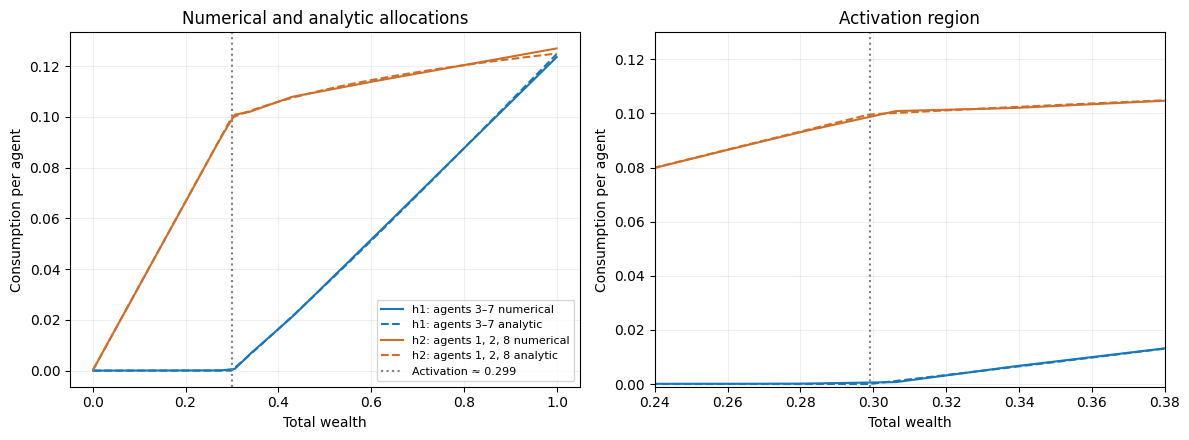

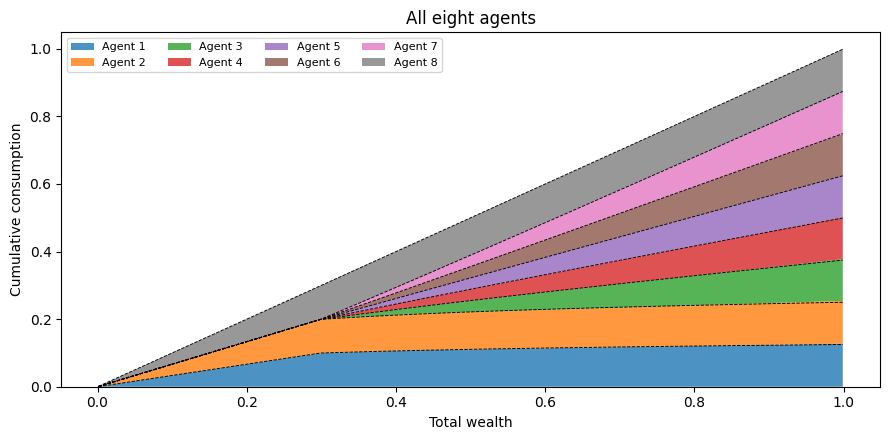

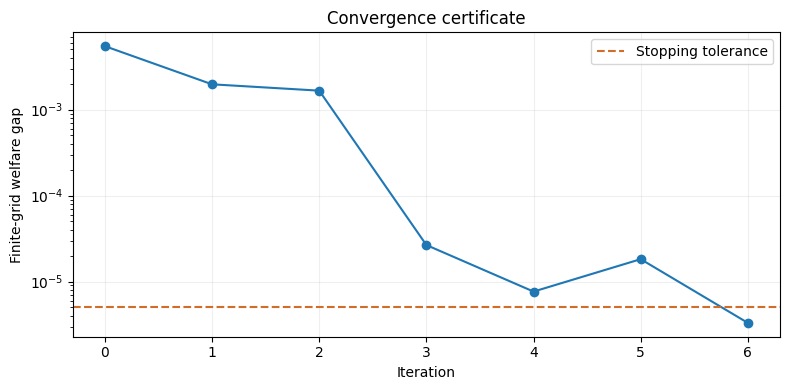

In [24]:
experiment.plots.show()


## 28. Optional: download the results

This creates a ZIP of the tables, diagnostics, and plots generated above. It offers a download in Colab;
it never asks for an upload. Skip this cell if you only want to read the notebook.

In [25]:
results_archive = experiment.downloads.download()


Results ZIP: /content/day4_results_download.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 29. Presentation conclusion

The complete eight-agent numerical allocation agrees with the analytic solution within the declared
tolerances. Below total wealth about 0.299, the analytic optimum gives consumption only to h2 agents;
above that level, both types receive consumption. Identical agents receive equal shares.
All budget, nonnegativity, and monotonicity checks pass. Remaining finite-grid welfare improvement is
bounded by approximately 3.31e-6. Mesh refinement belongs to Day 5.

The delegated Day 4 theory and computation are covered. A separate personal review by Parsa is not claimed.
Sources: supplied five-day plan p.3, replication guide sections 3–7, and Carlier–Lachapelle (2011), Example 2.

## Appendix A: analytic derivation

Prepared by Nouman with ChatGPT assistance under the reported authorization to
complete both roles. This is a derivation and verification of the printed model,
not a claim that Parsa conducted a separate calculation. The guide and earlier
Day 4 results were available; a blind comparison before seeing any output is not
claimed. Each rerun saves the theoretical table before calling the solver.

## 1. Reduce eight agents to two functions

There are five h1 agents (paper agents 3–7) and three h2 agents (1, 2, 8).
Each has Pareto weight one. Wealth S is uniform on [0,1], so wealth s equals rank r
in this experiment. These remain separate arrays in the program.

Within a type, utility functions and weights are identical. Strict concavity of
the logarithm means equalizing consumption within that type improves welfare
unless consumption was already equal. Averaging within a type preserves budgets,
nonnegativity, and monotonicity. Thus write b(s) for EACH h1 agent and a(s) for
EACH h2 agent. Their combined consumption must satisfy

$$5b(s)+3a(s)=s.$$

At a fixed wealth state, maximize

$$5\log(1+\sqrt{s}+b)+3\log(1+s^{2/3}+a).$$

## 2. Match the benefit of one extra unit

When both types receive positive consumption, the gain from an additional unit
must be equal; otherwise transferring a little consumption improves welfare:

$$\frac{1}{1+\sqrt{s}+b}=\frac{1}{1+s^{2/3}+a}.$$

Therefore a = b + sqrt(s) - s^(2/3). Substitute this into the budget:

$$b(s)=\max\left\{\frac{s+3(s^{2/3}-\sqrt{s})}{8},0\right\},
\qquad a(s)=\frac{s-5b(s)}{3}.$$

The maximum with zero enforces the consumption domain. The other allocation is
positive for s>0: on the interior it equals
[s+5(sqrt(s)-s^(2/3))]/8, whose terms are nonnegative on [0,1].

## 3. Explain the zero-consumption region

If b=0, the budget gives a=s/3. Keeping b at zero is optimal exactly when h1's
marginal utility is no larger than h2's marginal utility:

$$\frac{1}{1+\sqrt{s}}\leq\frac{1}{1+s^{2/3}+s/3}.$$

This is equivalent to s+3s^(2/3)-3sqrt(s)<=0. For positive s, put t=s^(1/6),
divide by t^3, and solve

$$t^3+3t-3=0,\qquad s_0=t^6\simeq0.298995684337.$$

The cubic is strictly increasing and has exactly one root in (0,1).
Below s0, each h2 agent receives s/3 and each h1 agent receives zero.
Above s0, both types receive consumption. At s=1, all eight receive 1/8.

## 4. Check monotonicity, rather than assuming it

Below s0, b'=0 and a'=1/3. Above s0:

$$b'(s)=\frac{1+2s^{-1/3}-(3/2)s^{-1/2}}{8},$$
$$a'(s)=\frac{1+(5/2)s^{-1/2}-(10/3)s^{-1/3}}{8}.$$

Multiply the numerators by t^3>0. For b', the resulting polynomial is
t^3+2t-1.5. It is increasing, and at t0 its value is 1.5-t0>0.
For a', the polynomial is t^3-(10/3)t+2.5. It is decreasing on [t0,1],
and its value at 1 is 1/6>0. Both derivatives are therefore positive.
The two formulas agree at s0, so there is no downward jump there.

The pointwise optima are feasible for the monotone problem. Consequently they
also solve the full finite-grid problem. Strict concavity gives a unique optimum
on a grid with positive probability weights. This shortcut depends on these
parameters and must be rechecked for other utilities or Pareto weights.

## 5. What the numerical certificate proves

On the fixed grid, concavity and an exact linear oracle imply

$$F(C)\leq F^*\leq F(C)+G(C),\qquad
G(C)=\sum_{j,i}\nabla F(C)_{ji}(V_{ji}-C_{ji}).$$

Here V maximizes the linear objective over all feasible allocations. The analytic
grid welfare must lie inside this interval, up to the recorded rounding tolerance.
This bounds welfare optimization error on the chosen grid. It does not bound the
error from replacing the continuous distribution by 400 midpoint nodes, and it
does not establish the same certificate for nonconcave utilities.

## Sources

Five-day plan, printed p.3, both Day 4 columns. Replication guide, sections 3–7
and milestone 5 (especially equations 12–13). Carlier–Lachapelle (2011), Example 2,
printed p.12, Figure 3 on p.7, algorithm on pp.6–8. The supplied PDFs are the
source edition; their SHA-256 hashes are recorded in source_manifest.json.


## Appendix B: presentation notes

## Your main conclusion

I completed the eight-agent Example 2 replication, including the analytic and
computational tasks under the delegated scope. The numerical solution matches the
analytic benchmark within our declared tolerances, and all feasibility and
validation checks pass. The remaining welfare improvement on the 400-state grid
is bounded by 3.31 × 10^-6, within numerical accuracy.

## A five-part presentation

1. **Question.** How should eight agents share total wealth when their two types
   have different rank-dependent logarithmic preferences? The objective is total
   weighted utility, subject to a budget in every state, nonnegative shares, and
   shares that do not fall as aggregate wealth rises.
2. **Two routes.** I reused the checked Days 1–3 model and conditional-gradient
   method, then derived a closed-form benchmark by reducing the eight agents to
   five identical h1 allocations b and three identical h2 allocations a.
   The budget is 5b+3a=s; positive allocations equalize marginal utility.
3. **Economic result.** Below s≈0.299, each h1 agent receives zero while each h2
   agent receives s/3. Above that level, both groups receive consumption. At s=1,
   all eight receive 0.125. Agents of the same type receive identical allocations.
4. **Numerical evidence.** The 400-state solver takes six updates. Welfare is
   4.146769154342 versus analytic grid welfare 4.146770230933. The actual welfare
   difference, 1.08e-6, is below the certified gap, 3.31e-6. Maximum allocation
   error is 0.002013, below the declared 0.0025 tolerance. The budget residual is
   5.55e-16. Gradient, LP, scalar-root, and small direct-optimizer checks pass.
5. **Scope and next step.** These checks establish the baseline on this finite
   grid. Day 5 should refine the grid and test stability before adapting the
   method to Friedman–Savage preferences or lotteries. The concave certificate
   must not be carried over to a nonconcave objective without a new argument.

## Figures to show

- results/allocation_overlay.png: solid numerical and dashed analytic curves,
  with an activation-region close-up. Lines represent consumption PER agent.
- results/cumulative_allocations.png: eight colored bands; band thickness is
  individual consumption and dashed boundaries are the analytic comparison.
- results/convergence.png: the gap falls below the chosen stopping threshold.

Use results/comparison_table.csv for numerical versus analytic midpoint values.
Use results/analytic_benchmark_table.csv for clean theoretical examples at exact
wealth levels such as 0.1, 0.5, and 1. These are different tables; label them.

## Questions you should be able to answer

**Why are there only two different curves?** Within each type, preferences and
weights are identical. Strict concavity makes equal allocation within each type
optimal; the eight agents are still modeled explicitly.

**Does equal Pareto weight mean equal consumption?** No. Equal weights count
utilities equally, but different marginal utilities can imply different shares.

**Why do the h1 agents get nothing at low wealth?** At zero h1 consumption,
the next unit benefits h2 more until the marginal utilities meet at the threshold.
This is a feature of the stated preferences, not a general recommendation for
wealth distribution or evidence that one type deserves more.

**Why does the numerical curve have tiny positive values below activation?**
The algorithm moves by convex combinations and stops at a positive gap tolerance.
The maximum leakage is below 0.000544. Strictly positive is not an appropriate
numerical test of the theoretical activation threshold.

**Why can allocation error be 0.002 even when welfare error is tiny?** Welfare
can be relatively flat around its optimum; a small welfare error does not imply
the same numerical magnitude for consumption error. Both are reported separately.

**Does the gap certify the continuous problem?** No. The exact 400-node welfare
exceeds the estimated continuous reference by 4.49e-5. That quadrature difference
is separate from the solver's 1.08e-6 welfare error on the grid.

**Did Parsa independently verify this result?** These theory and code deliverables
were prepared with ChatGPT assistance under the reported delegation. Independent
formulation checks were performed; a separate personal review is not claimed.

## Short closing you can adapt

Day 4 gives us a reproducible eight-agent baseline with an analytic benchmark,
verified constraints, and a finite-grid welfare bound. This is enough to mark the
delegated Day 4 deliverables complete and proceed to the Day 5 stability checks.
